Notebook to generate the figures in the readme.md

In [1]:
from viz import * 
import numpy as np
import pandas as pd
import seaborn as sns
import geopandas as gpd 
import matplotlib as mpl
import matplotlib.pyplot as plt 
import matplotlib.patches as mpatches
from shapely.geometry import Polygon, MultiPolygon
import dataframe_image as dfi
from epiweeks import Week 
from aux_func import get_data, code_to_state, color_palette, estado_para_regiao, rename_models

# Definir a cor das bordas (spines) como cinza
mpl.rcParams['axes.edgecolor'] = 'gray'

# Definir a cor das linhas dos ticks maiores e menores como cinza
mpl.rcParams['xtick.color'] = 'gray'
mpl.rcParams['ytick.color'] = 'gray'
mpl.rcParams['xtick.labelcolor'] = 'black'
mpl.rcParams['ytick.labelcolor'] = 'black'
plt.rcParams['axes.labelsize'] = 16 # Axis labels
plt.rcParams['xtick.labelsize'] = 14  # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 14  # Y-axis tick labels
plt.rcParams['font.size'] = 16  # General font size
FONT = 12

In [2]:
challenge = 'dengue_state'

In [3]:
df_dengue = get_data(challenge)
df_dengue.date = pd.to_datetime(df_dengue.date)

df_dengue.head()

,date,adm_1,casos
0,2010-01-03,11,2456
1,2010-01-03,12,760
2,2010-01-03,13,155
3,2010-01-03,14,25
4,2010-01-03,15,115


In [4]:
df_preds = pd.read_csv(f'./predictions/predictions_all_models_{challenge}.csv.gz', index_col = 'Unnamed: 0')
df_preds.date = pd.to_datetime(df_preds.date)
df_preds['model'] = df_preds['model'].replace(rename_models)
df_preds.head()

,date,lower_95,lower_90,lower_80,lower_50,pred,upper_50,upper_80,upper_90,upper_95,adm_1,id,validation,wis,model
0,2022-10-09,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,12,6822,1,95.67,ISI
1,2022-10-16,37.019327,43.295517,51.743385,66.653189,83.207109,100.790847,116.992117,126.864602,134.406880,12,6822,1,95.67,ISI
2,2022-10-23,55.945220,68.411390,84.200302,108.887826,135.698419,163.344639,189.017119,205.765306,218.575663,12,6822,1,95.67,ISI
3,2022-10-30,58.185781,69.697014,83.792687,107.076328,132.601767,158.745145,184.276095,201.204977,212.912726,12,6822,1,95.67,ISI
4,2022-11-06,58.634062,68.591352,80.855678,101.969117,125.548661,150.259612,174.517426,190.524410,202.512661,12,6822,1,95.67,ISI


In [5]:
df_preds.model.unique()

<ArrowStringArray>
[             'ISI',           'PURDUE',     'FIOCRUZ_MARD',
              'BSC',        'EMAP_BLUE',       'LNCC_ARP26',
            'PROCC',            'UNESP',             'IFGW',
       'DS-OKSTATE',             'CERI',         'NUS-CERM',
       'LNCC_SURGE',           'PUCRIO',        'EMAP_LSTM',
         'EMAP_XGB',          'UNIFESP',    'UNI_DEL_VALLE',
    'LNCC_CLIDENGO',     'EMAP_TIMESFM', 'FIOCRUZ_ZEROLAGS',
          'CORNELL',      'EMAP_SAKHAL',         'RKI_LSTM',
     'EMAP_SARIMAX',             'AFYA',           'RKI_PH',
     'EMAP_PROPHET']
Length: 28, dtype: str

In [6]:
df_rank = pd.read_csv(f'predictions/rank_ratio_{challenge}.csv')

df_rank['model'] = df_rank['model'].replace(rename_models)

df_rank['rank'] = df_rank.groupby(['validation', 'adm_1'])['wis_ratio'].rank(ascending=True, method='min')
#df_rank['region'] = df_rank['region'].replace(rename_regions)

df_rank.head()

,model,adm_1,validation,wis,wis_baseline,wis_ratio,region,rank
0,UNIFESP,11,1,205.38,101.894535,2.015613,North,25.0
1,UNIFESP,11,2,68.46,31.277812,2.188772,North,19.0
2,UNIFESP,11,3,30.97,24.740000,1.251819,North,20.0
3,UNIFESP,11,4,42.33,26.550000,1.594350,North,19.0
4,UNIFESP,12,1,37.72,30.964984,1.218150,North,14.0


In [7]:
df_rank.model.unique()

<ArrowStringArray>
[         'UNIFESP',             'AFYA',              'BSC',
             'CERI',          'CORNELL',     'EMAP_PROPHET',
     'EMAP_SARIMAX',        'EMAP_LSTM',         'EMAP_XGB',
        'EMAP_BLUE',      'EMAP_SAKHAL',     'FIOCRUZ_MARD',
 'FIOCRUZ_ZEROLAGS',             'IFGW',              'ISI',
    'LNCC_CLIDENGO',       'LNCC_ARP26',       'LNCC_SURGE',
         'NUS-CERM',            'PROCC',           'PUCRIO',
           'PURDUE',           'RKI_PH',         'RKI_LSTM',
            'UNESP',    'UNI_DEL_VALLE',       'DS-OKSTATE',
     'EMAP_TIMESFM']
Length: 28, dtype: str

## Plot overall performance:

EMAP_PROPHET
IFGW
LNCC_ARP26
PURDUE
RKI_PH


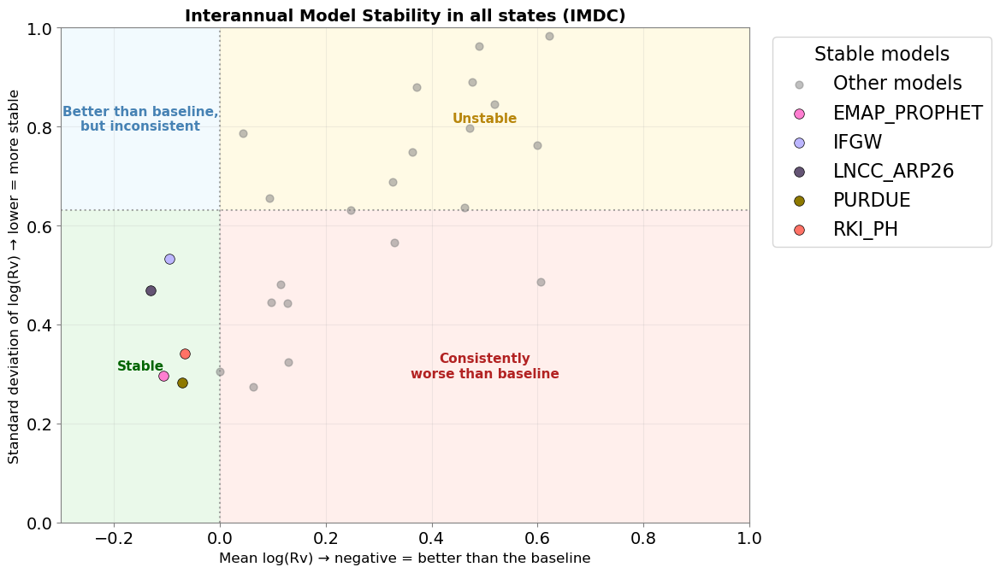

In [8]:
fig, ax, df_agg = plot_model_scatter(
    df_rank,
    rename_models=rename_models,
    baseline_model="PROCC",
    exclude_adm1=32,
    title="Interannual Model Stability in all states (IMDC)",
    xlabel="Mean log(Rv) → negative = better than the baseline",
    ylabel="Standard deviation of log(Rv) → lower = more stable",
    xlim=(-0.3, 1),
    ylim=(0, 1),
    figsize=(12, 7),
    savepath=f'figures/scatter_stable_{challenge}.png',
    color_palette=color_palette)

### Violin plots:

/home/eduardocorrea/Documentos/analises_3rd_IMDC/viz.py:900: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


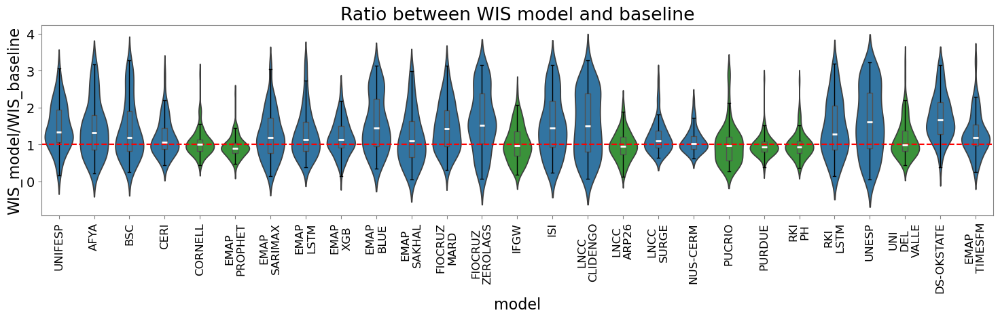

(<Figure size 1500x500 with 1 Axes>,
 <Axes: title={'center': 'Ratio between WIS model and baseline'}, xlabel='model', ylabel='WIS_model/WIS_baseline'>)

In [9]:
plot_violin(df_rank.loc[df_rank.model != 'PROCC'], region = None, challenge=challenge)

/home/eduardocorrea/Documentos/analises_3rd_IMDC/viz.py:900: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


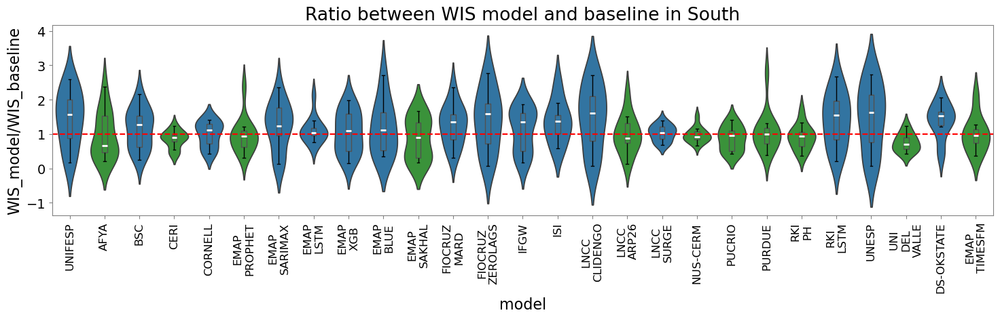

/home/eduardocorrea/Documentos/analises_3rd_IMDC/viz.py:900: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


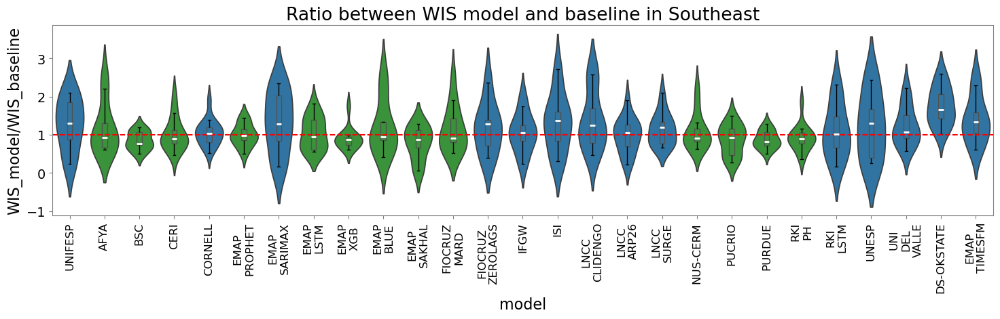

/home/eduardocorrea/Documentos/analises_3rd_IMDC/viz.py:900: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


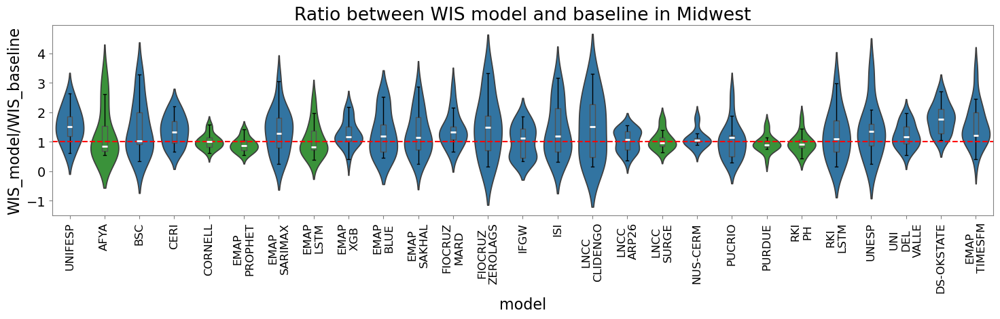

/home/eduardocorrea/Documentos/analises_3rd_IMDC/viz.py:900: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


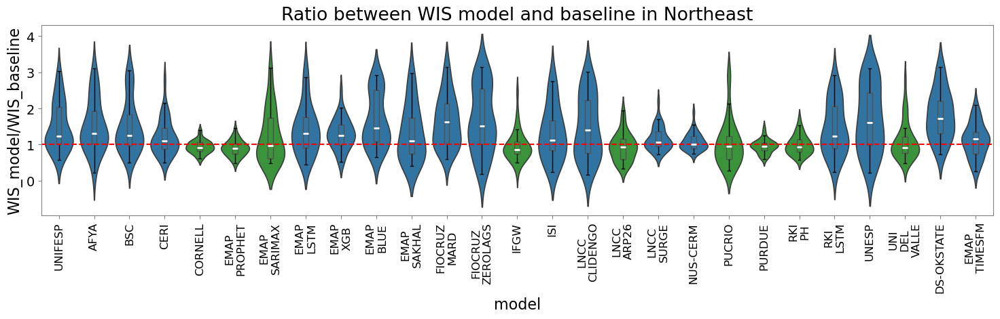

/home/eduardocorrea/Documentos/analises_3rd_IMDC/viz.py:900: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


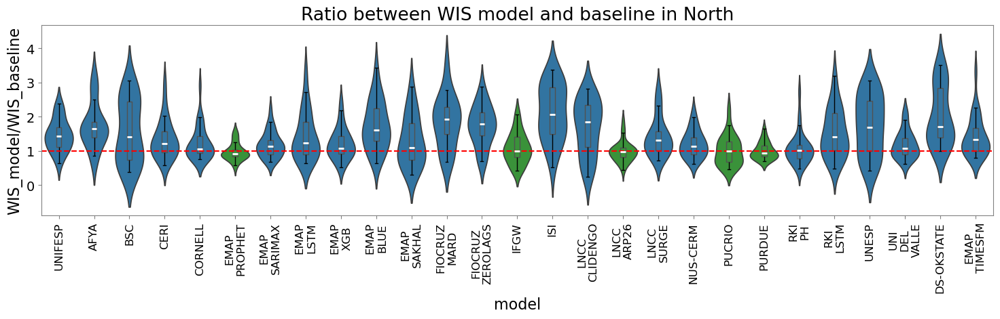

(<Figure size 1500x500 with 1 Axes>,
 <Axes: title={'center': 'Ratio between WIS model and baseline in North'}, xlabel='model', ylabel='WIS_model/WIS_baseline'>)

In [10]:
plot_violin(df_rank.loc[df_rank.model != 'PROCC'], region = 'South', challenge=challenge)
plot_violin(df_rank.loc[df_rank.model != 'PROCC'], region = 'Southeast',challenge=challenge)
plot_violin(df_rank.loc[df_rank.model != 'PROCC'], region = 'Midwest',challenge=challenge)
plot_violin(df_rank.loc[df_rank.model != 'PROCC'], region = 'Northeast',challenge=challenge)
plot_violin(df_rank.loc[df_rank.model != 'PROCC'], region = 'North',challenge=challenge)

### Heatmaps

In [11]:
df_summary = (
    df_rank
    .groupby(["adm_1", "model"], as_index=False)
    .agg(
        geometric_mean_ratio=("wis_ratio", lambda x: np.exp(np.mean(np.log(x)))),
    )
    .sort_values(["adm_1", "geometric_mean_ratio"])
)

column = 'geometric_mean_ratio'

df_summary["rank"] = (
    df_summary.groupby(["adm_1"])[[column]].rank(method="min", ascending=True)
)

df_summary = df_summary.loc[(df_summary.adm_1 != 32)]
df_summary.head()

,adm_1,model,geometric_mean_ratio,rank
21,11,PUCRIO,0.789304,1.0
16,11,LNCC_ARP26,0.800598,2.0
14,11,IFGW,0.845450,3.0
24,11,RKI_PH,0.893327,4.0
7,11,EMAP_PROPHET,0.894684,5.0


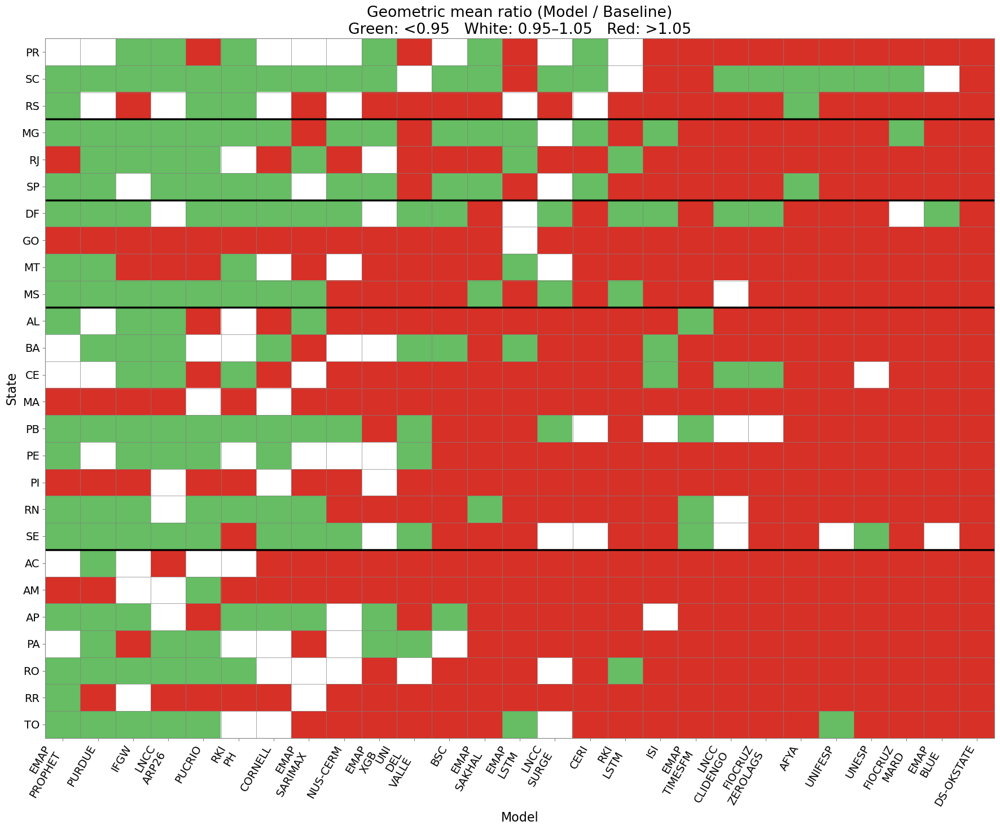

In [12]:
df_summary['adm_1'] = df_summary['adm_1'].replace(code_to_state)
ranking = plot_matrix(df_summary.loc[ (df_summary.model != 'PROCC')]
, [ 'PR', 'SC' ,'RS',
            'MG', 'RJ', 'SP',
            'DF', 'GO', 'MT', 'MS',
            'AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE',
            'AC', 'AM', 'AP', 'PA', 'RO', 'RR', 'TO'],
        figsize=(18, 15),
        challenge=challenge)

In [13]:
order = {
    'south': ['PR', 'SC' ,'RS'],
    'southeast': ['MG', 'RJ', 'SP'],
    'midwest': ['DF', 'GO', 'MT', 'MS'],
    'northeast': ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'],
    'north': ['AC', 'AM', 'AP', 'PA', 'RO', 'RR', 'TO'] } 

In [14]:
for region in order.keys(): 
    plot_geometric_ratio_heatmap(
        df_summary.loc[ (df_summary.model != 'PROCC')],
        order[region],
        region,
        figsize=(25, 5),
        challenge=challenge
    )

## Plots Best models by state: 

In [15]:
df_bm_st = df_summary.loc[df_summary['rank'] ==1].rename(columns = {'model': 'best_model'})
df_bm_st['state'] = df_bm_st['adm_1'].replace(code_to_state)

df_bm_st.head()

,adm_1,best_model,geometric_mean_ratio,rank,state
21,RO,PUCRIO,0.789304,1.0,RO
50,AC,PURDUE,0.940250,1.0,AC
77,AM,PUCRIO,0.816319,1.0,AM
91,RR,EMAP_PROPHET,0.905822,1.0,RR
133,PA,PUCRIO,0.861798,1.0,PA


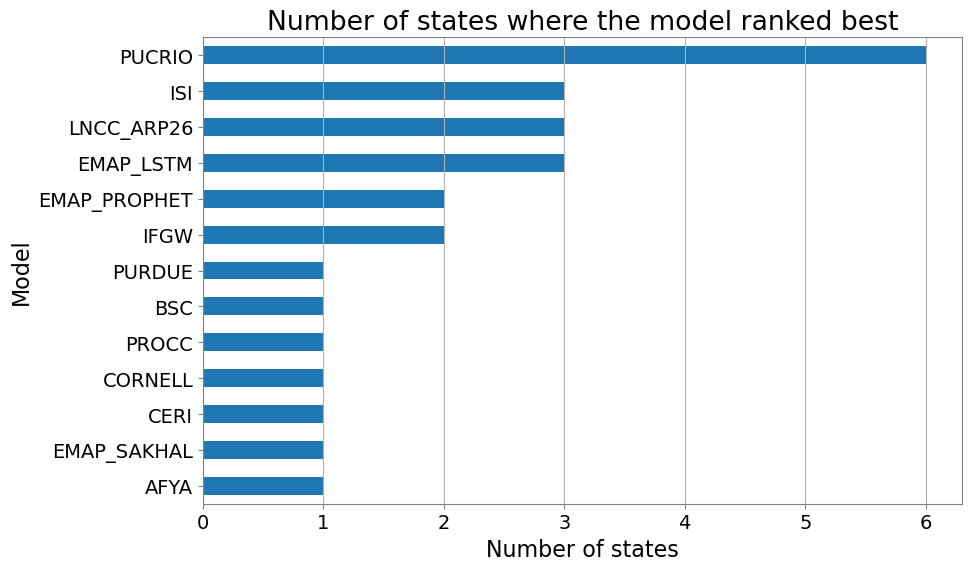

In [16]:
barplot_best_models(
    df_bm_st,
    challenge=challenge,
    model_col="best_model") 

Plot map: 

In [17]:
def remove_holes(geom):
    if geom.geom_type == "Polygon":
        return Polygon(geom.exterior)  # mantém só o contorno externo
    elif geom.geom_type == "MultiPolygon":
        # acessa cada polígono dentro do MultiPolygon
        return MultiPolygon([Polygon(p.exterior) for p in geom.geoms])
    else:
        return geom

In [18]:
df_muni = gpd.read_file('../imdc_2026/data/shape_muni.gpkg')

df_muni["geometry"] = df_muni.buffer(0)

df_uf = df_muni.dissolve(by="uf")

df_uf["geometry"] = df_uf["geometry"].apply(remove_holes)

df_uf["geometry"] = df_uf.buffer(1e-9).buffer(-1e-9)

# reset index if you want 'uf' back as a column
df_uf = df_uf.reset_index()

df_uf_m = df_uf.merge(df_bm_st, left_on = 'uf', right_on = 'state')

df_uf_m.head()

/tmp/ipykernel_20690/1175374976.py:9: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  df_uf["geometry"] = df_uf.buffer(1e-9).buffer(-1e-9)


,uf,geometry,geocode,geocode_name,uf_code,adm_1,best_model,geometric_mean_ratio,rank,state
0,AC,"POLYGON ((-70.51515 -7.79238, -70.05498 -7.845...",1200013,Acrelândia,12,AC,PURDUE,0.940250,1.0,AC
1,AL,"MULTIPOLYGON (((-38.23759 -9.3298, -38.23759 -...",2700102,Água Branca,27,AL,IFGW,0.762967,1.0,AL
2,AM,"POLYGON ((-72.37321 -4.83344, -72.37321 -4.833...",1300029,Alvarães,13,AM,PUCRIO,0.816319,1.0,AM
3,AP,"MULTIPOLYGON (((-54.87625 2.42669, -54.87625 2...",1600055,Serra do Navio,16,AP,BSC,0.765793,1.0,AP
4,BA,"MULTIPOLYGON (((-46.57715 -11.36086, -46.57715...",2900108,Abaíra,29,BA,ISI,0.711791,1.0,BA


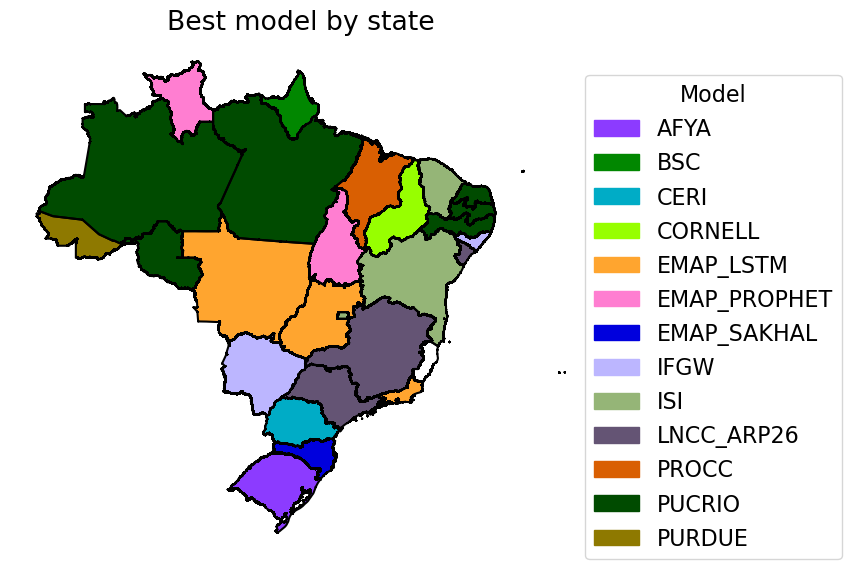

In [19]:
_, ax = plt.subplots(figsize = (7.5, 7.5))

handles = []  # aqui guardamos os patches da legenda

for model in np.sort(df_uf_m.best_model.unique()): 

    df_ = df_uf_m.loc[df_uf_m.best_model == model]
    
    #model = df_.best_model.values[0]

    df_.plot(color = color_palette[model], label = model, ax=ax)

    if not any(h.get_label() == model for h in handles):
        handles.append(mpatches.Patch(color=color_palette[model], label=model))

df_uf.boundary.plot(ax=ax, color = 'black')
ax.axis('off')

ax.legend(handles = handles, title = 'Model', bbox_to_anchor = (1.45, 0.95))

ax.set_title('Best model by state')

plt.savefig(f'figures/map_best_model_{challenge}.png', dpi = 400, bbox_inches = 'tight')
plt.show()

### Best model by region:

In [20]:
df_best_region_model = df_rank.groupby(["region", "model"], as_index=False).agg(
        arithmetic_mean_ratio=("wis_ratio", "mean"),
        geometric_mean_ratio=("wis_ratio", lambda x: np.exp(np.mean(np.log(x)))),
    ).sort_values(["region", "geometric_mean_ratio"]) 


df_best_region_model["rank"] = (
    df_best_region_model.groupby(["region"])[[column]].rank(method="min", ascending=True)
)

df_best_region_model.head()

,region,model,arithmetic_mean_ratio,geometric_mean_ratio,rank
14,Midwest,IFGW,0.996070,0.838807,1.0
7,Midwest,EMAP_PROPHET,0.897686,0.867344,2.0
24,Midwest,RKI_PH,0.947156,0.892820,3.0
22,Midwest,PURDUE,0.939682,0.894167,4.0
21,Midwest,PUCRIO,1.178763,0.947244,5.0


### PLot Medal Board: 

In [21]:
df_top_3 = df_summary.loc[df_summary['rank'].isin([1, 2, 3])]
df_top_3['state'] = df_top_3['adm_1'].replace(code_to_state)

df_top_3.head()

,adm_1,model,geometric_mean_ratio,rank,state
21,RO,PUCRIO,0.789304,1.0,RO
16,RO,LNCC_ARP26,0.800598,2.0,RO
14,RO,IFGW,0.845450,3.0,RO
50,AC,PURDUE,0.940250,1.0,AC
49,AC,PUCRIO,0.969428,2.0,AC


In [22]:
ranked_models = df_top_3.pivot(index='rank', columns='state', values='model')

ranked_models.head()

state,AC,AL,AM,AP,BA,CE,DF,GO,MA,MG,...,PR,RJ,RN,RO,RR,RS,SC,SE,SP,TO
rank,,,,,,,,,,,,,,,,,,,,,
1.0,PURDUE,IFGW,PUCRIO,BSC,ISI,ISI,ISI,EMAP_LSTM,PROCC,LNCC_ARP26,...,CERI,EMAP_LSTM,PUCRIO,PUCRIO,EMAP_PROPHET,AFYA,EMAP_SAKHAL,LNCC_ARP26,LNCC_ARP26,EMAP_PROPHET
2.0,PUCRIO,EMAP_PROPHET,PROCC,EMAP_XGB,IFGW,LNCC_ARP26,IFGW,PROCC,PUCRIO,RKI_PH,...,EMAP_XGB,RKI_LSTM,EMAP_TIMESFM,LNCC_ARP26,EMAP_SARIMAX,RKI_PH,AFYA,EMAP_SARIMAX,PUCRIO,LNCC_ARP26
3.0,PROCC,EMAP_TIMESFM,IFGW,EMAP_PROPHET,LNCC_ARP26,LNCC_CLIDENGO,RKI_LSTM,EMAP_PROPHET,CORNELL,PUCRIO,...,LNCC_ARP26,PUCRIO,RKI_PH,IFGW,PROCC,PUCRIO,UNESP,EMAP_PROPHET,EMAP_SAKHAL,EMAP_LSTM


In [23]:
for region in order.keys(): 
    styler = plot_medal_board(ranked_models[order[region]],) 
    dfi.export(styler, f"figures/medals_{region}_{challenge}.png", dpi = 400,  table_conversion="matplotlib",
)

### Models with mean ratio >1 

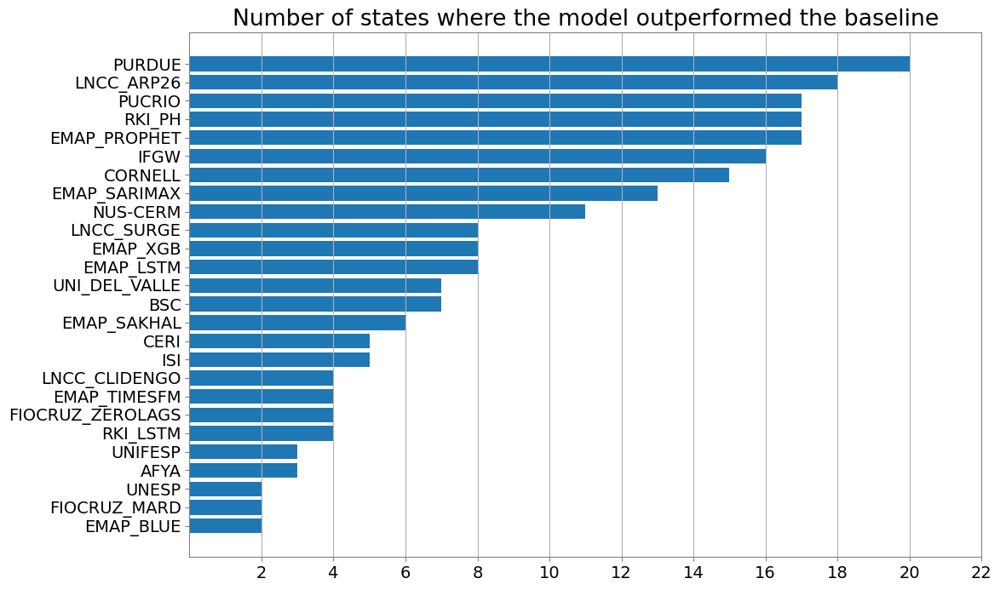

In [24]:
df_agg = df_summary.loc[df_summary.geometric_mean_ratio < 1].groupby(['model'])[['adm_1']].count()
df_agg = df_agg.sort_values(by = 'adm_1')

_, ax= plt.subplots(figsize = (12, 8))

ax.barh(df_agg.index, df_agg.adm_1)

ax.grid(axis = 'x')
ax.set_title('Number of states where the model outperformed the baseline')
ax.set_xticks(np.arange(2, 23, step = 2))

plt.savefig(f'figures/n_states_out_base_by_model_{challenge}.png', dpi = 400,  bbox_inches = 'tight')

plt.show()

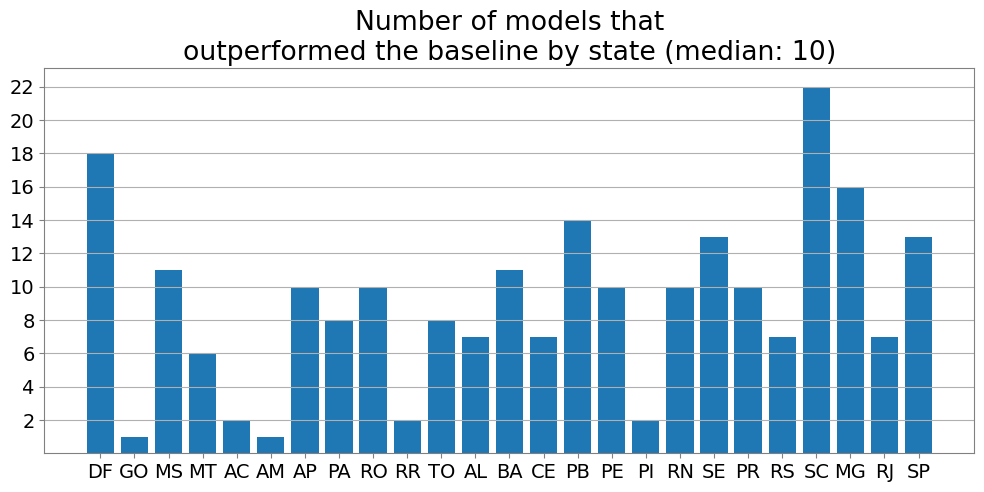

In [25]:
df_agg = df_summary.loc[df_summary.geometric_mean_ratio < 1].groupby(['adm_1'])[['model']].count().reset_index()
df_agg['adm_1'] = df_agg['adm_1'].replace(code_to_state)

# Cria a coluna de região e ordena
df_agg['regiao'] = df_agg['adm_1'].map(estado_para_regiao)
df_agg = df_agg.sort_values(by=['regiao', 'adm_1'])

# Plotagem
_, ax = plt.subplots(figsize=(12, 5))
ax.bar(df_agg.adm_1, df_agg.model)
ax.set_title(f'Number of models that\noutperformed the baseline by state (median: {int(np.median(df_agg.model))})')
ax.set_yticks(np.arange(2, 23, step = 2))

ax.grid(axis='y')

plt.savefig(f'figures/n_models_out_base_by_state_{challenge}.png', dpi = 400)

### Zoom: 

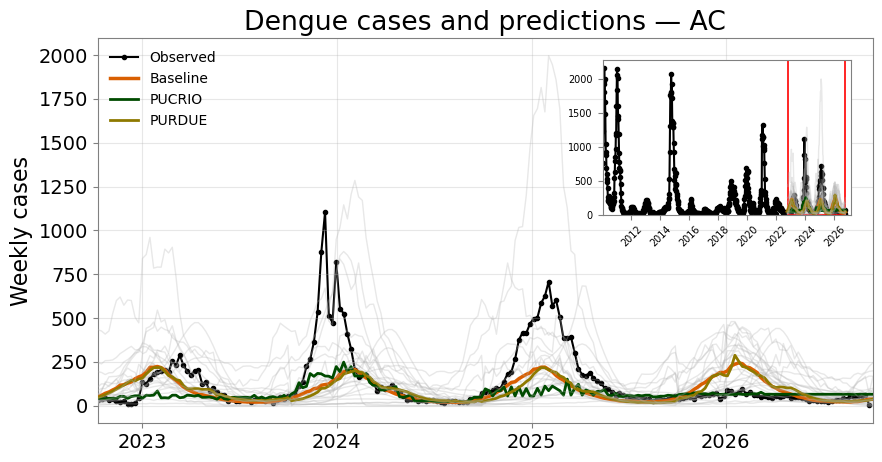

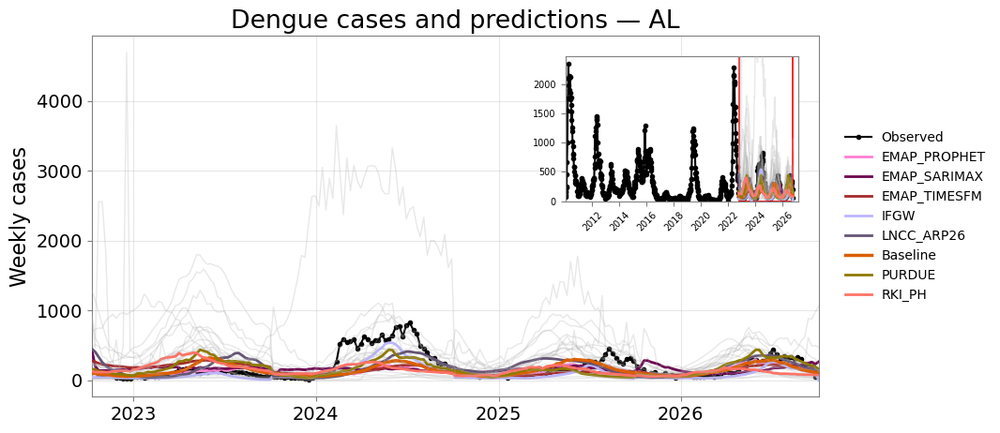

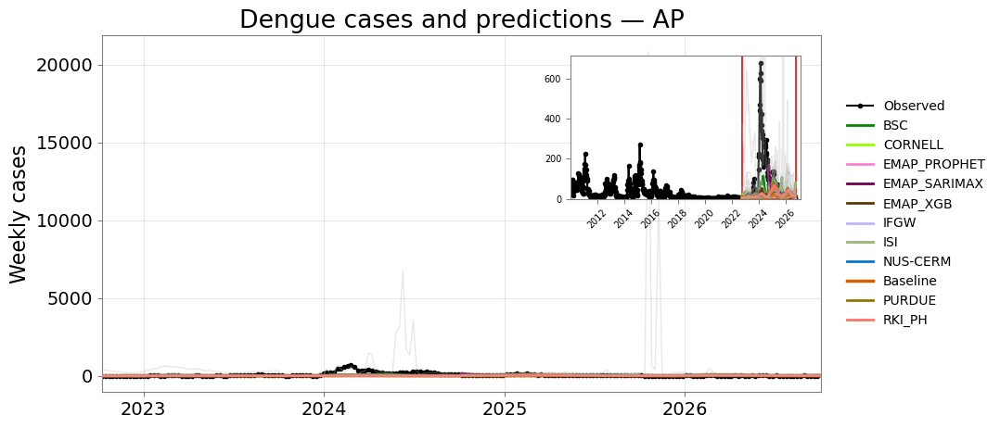

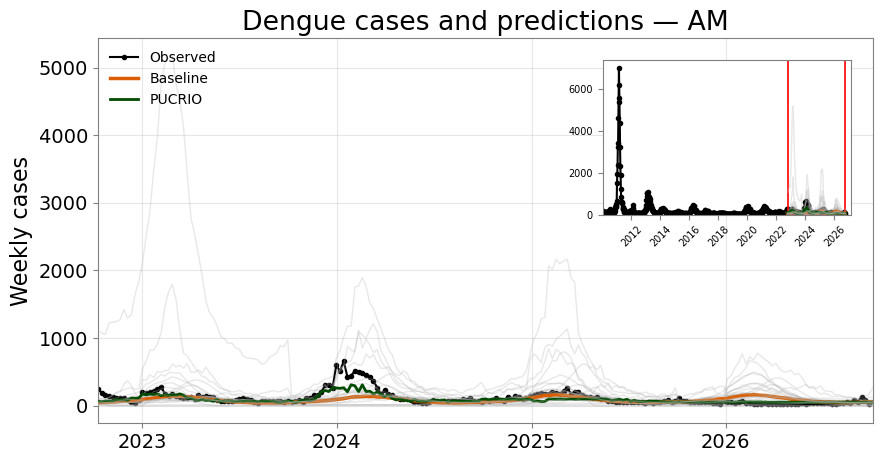

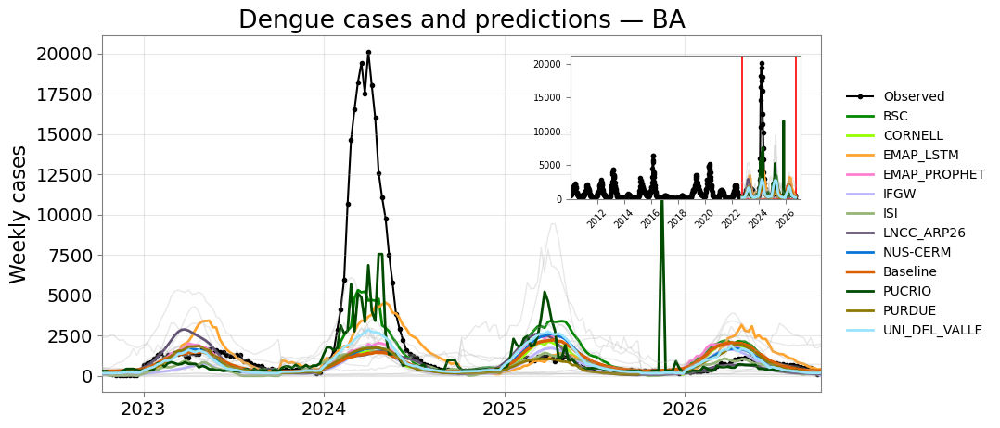

...

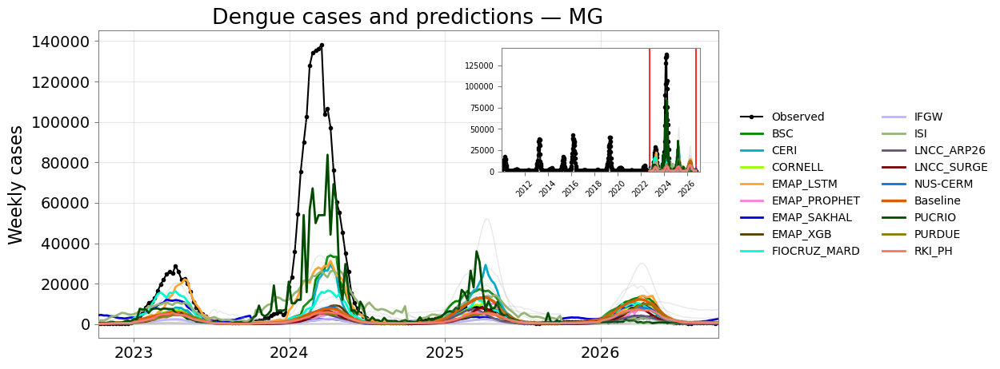

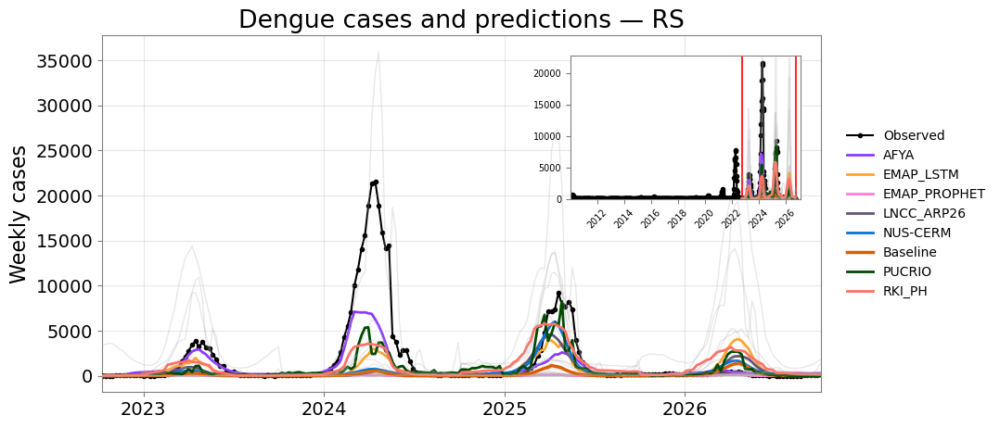

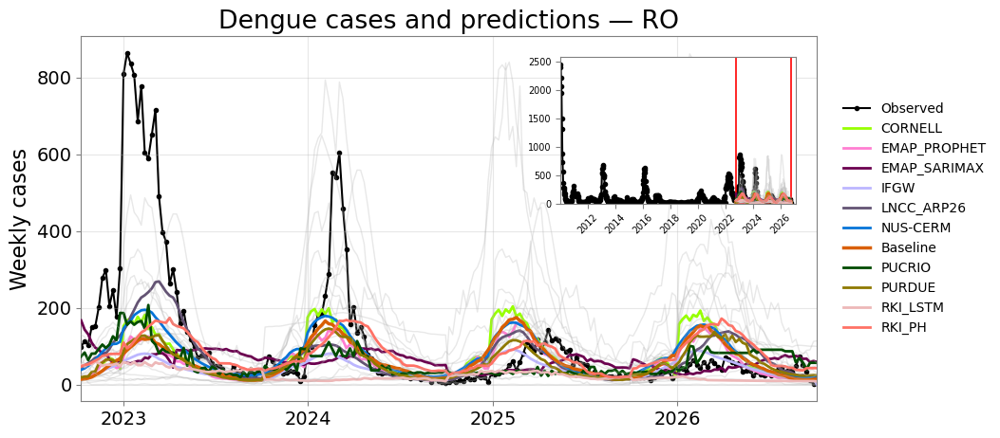

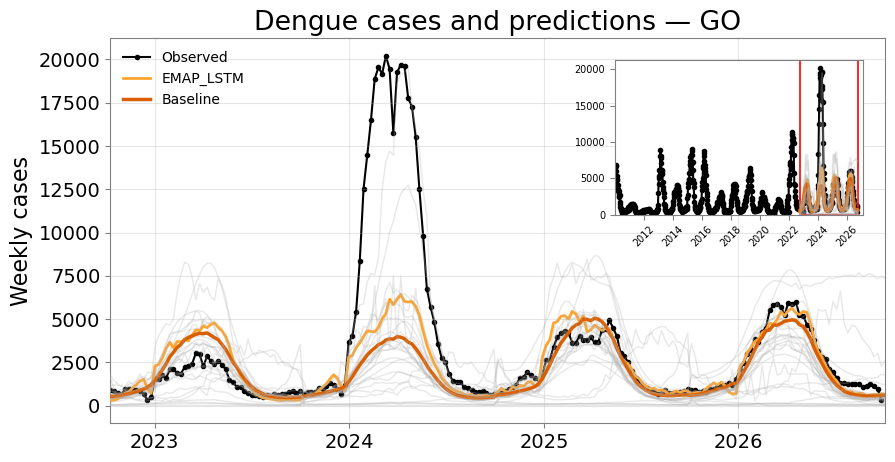

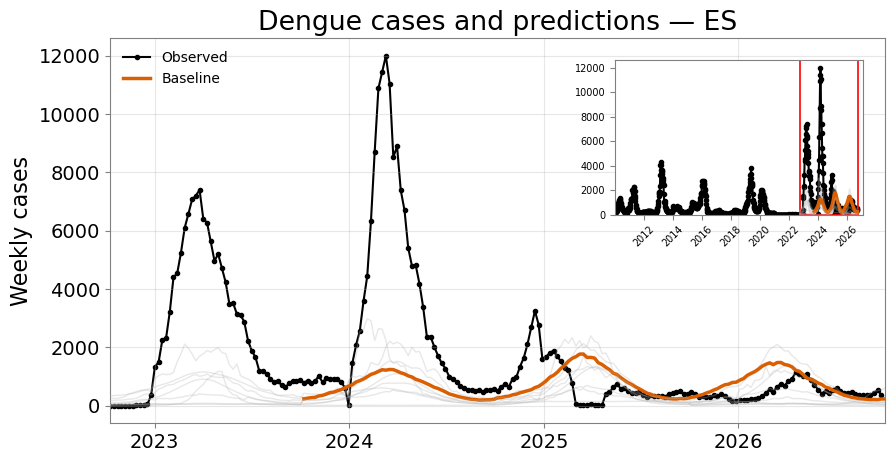

In [26]:
zoom_start = pd.to_datetime(Week(2022,41).startdate())
zoom_end = pd.to_datetime(Week(2026,40).startdate())

for state in df_preds.adm_1.unique(): 
    plot_zoom_state(
        state,
        df_dengue,
        df_preds,
        df_summary,
        code_to_state,
        color_palette,
        zoom_start,
        zoom_end,
        model_base="PROCC",
        figsize=(10, 5),
        savepath=f'figures/zoom_{state}_{challenge}.png'
        )

    plt.show()
    plt.close()

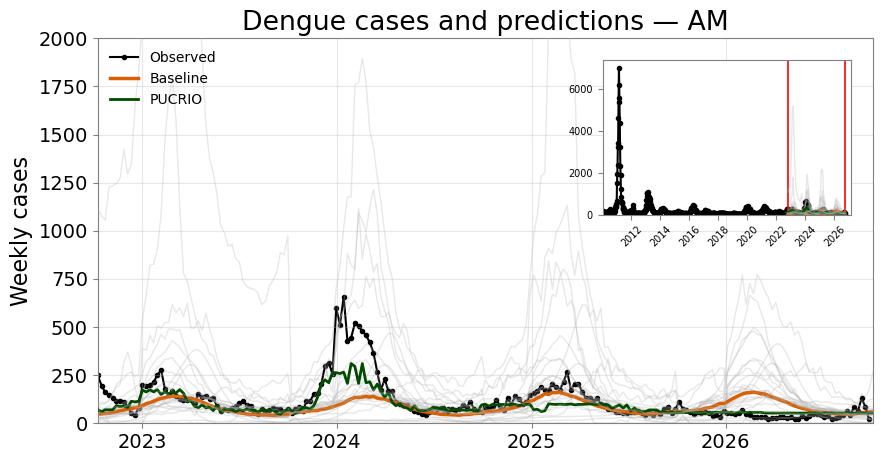

In [27]:
zoom_start = pd.to_datetime(Week(2022,41).startdate())
zoom_end = pd.to_datetime(Week(2026,40).startdate())

for state in [13]: 
    plot_zoom_state(
        state,
        df_dengue,
        df_preds,
        df_summary,
        code_to_state,
        color_palette,
        zoom_start,
        zoom_end,
        model_base="PROCC",
        figsize=(10, 5),
        savepath=f'figures/zoom_{state}_{challenge}.png', 
        ylim = 2000
        )

    plt.show()
    plt.close()

### Rankplots: 

In [28]:
df_rank.loc[df_rank.model !='PROCC']

,model,adm_1,validation,wis,wis_baseline,wis_ratio,region,rank
0,UNIFESP,11,1,205.38,101.894535,2.015613,North,25.0
1,UNIFESP,11,2,68.46,31.277812,2.188772,North,19.0
2,UNIFESP,11,3,30.97,24.740000,1.251819,North,20.0
3,UNIFESP,11,4,42.33,26.550000,1.594350,North,19.0
4,UNIFESP,12,1,37.72,30.964984,1.218150,North,14.0
...,...,...,...,...,...,...,...,...
2942,EMAP_TIMESFM,52,4,355.84,293.550000,1.212196,Midwest,4.0
2943,EMAP_TIMESFM,53,1,221.44,186.250513,1.188936,Midwest,15.0
2944,EMAP_TIMESFM,53,2,4960.70,4186.771408,1.184851,Midwest,19.0
2945,EMAP_TIMESFM,53,3,996.45,296.110000,3.365135,Midwest,28.0


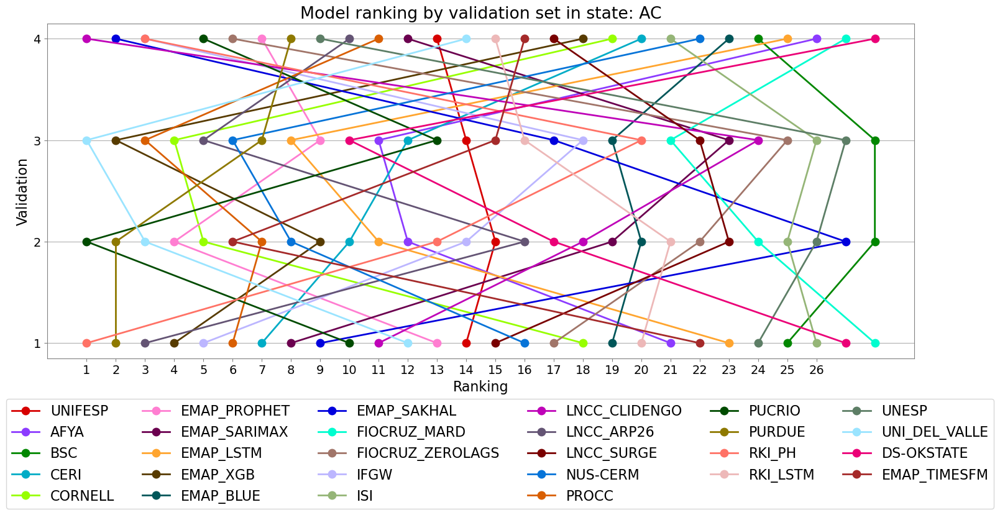

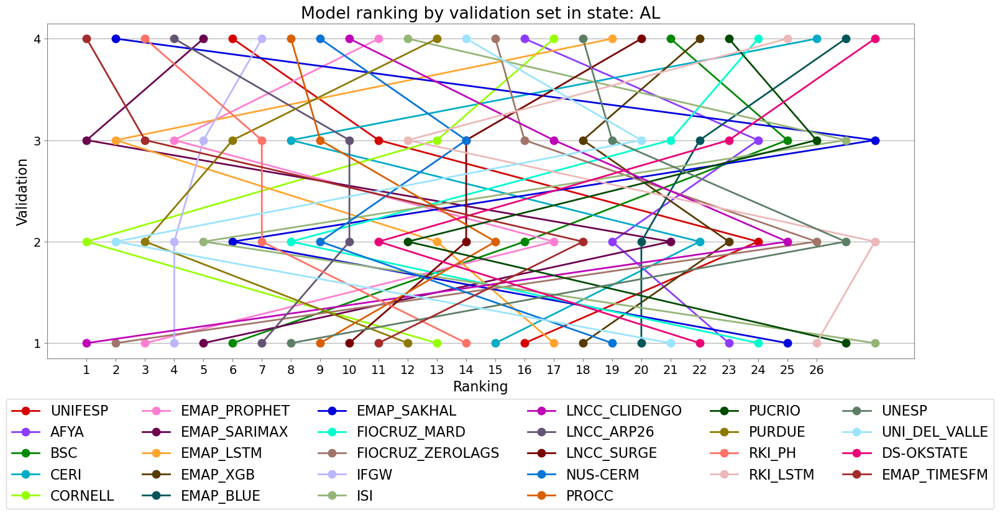

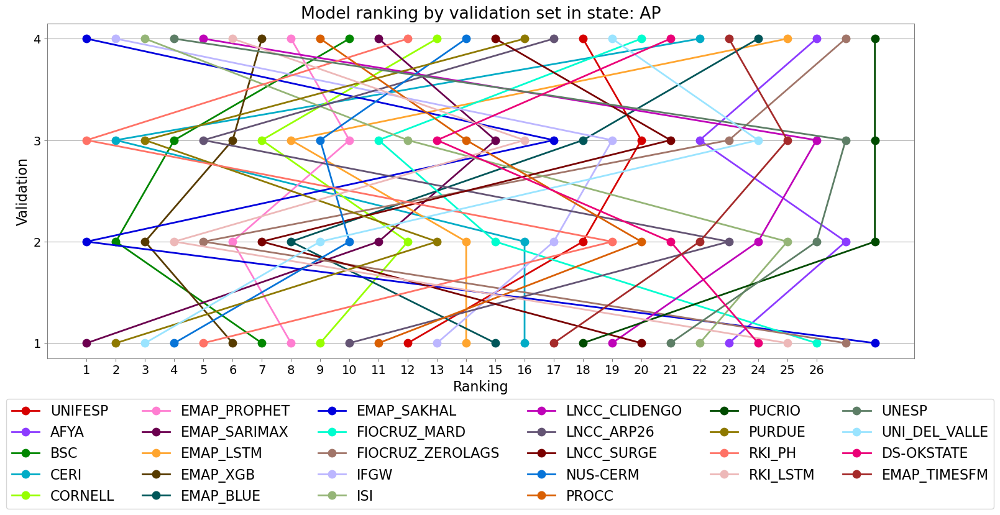

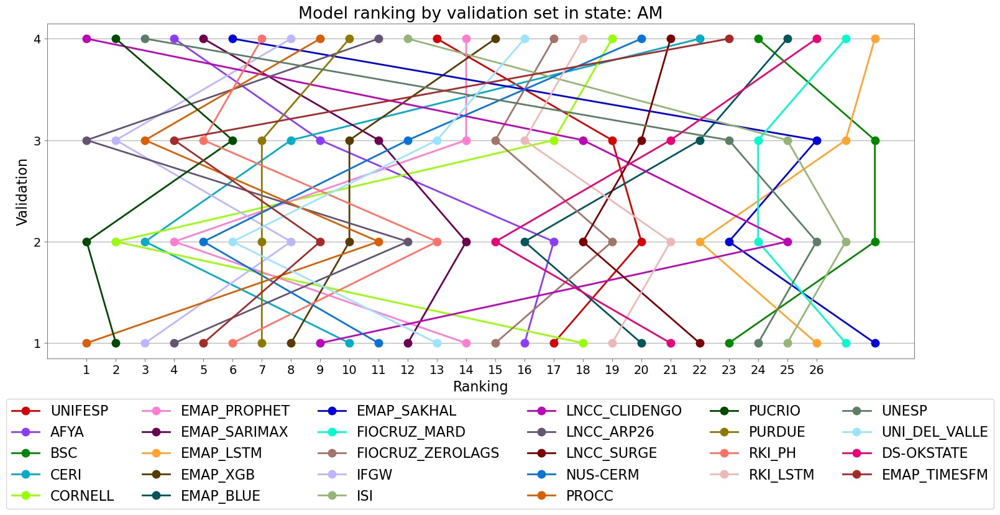

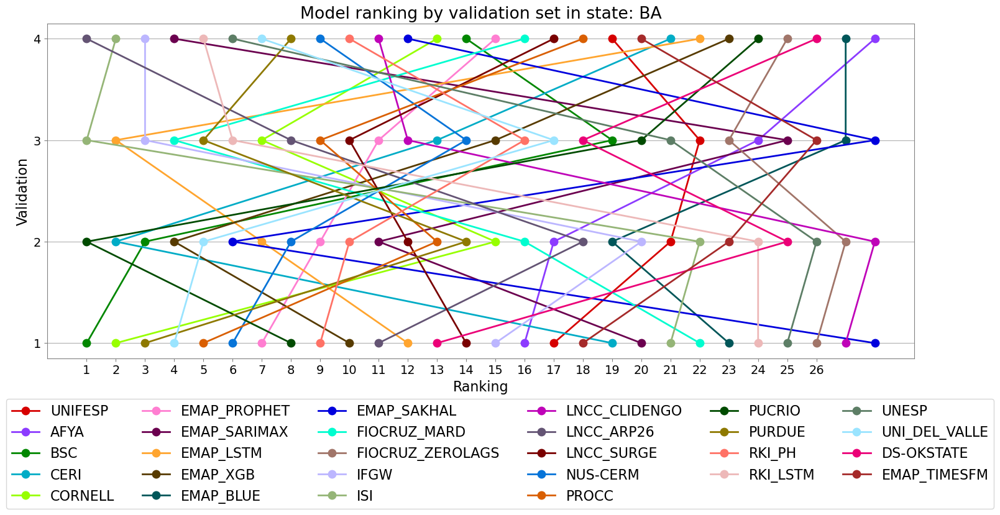

...

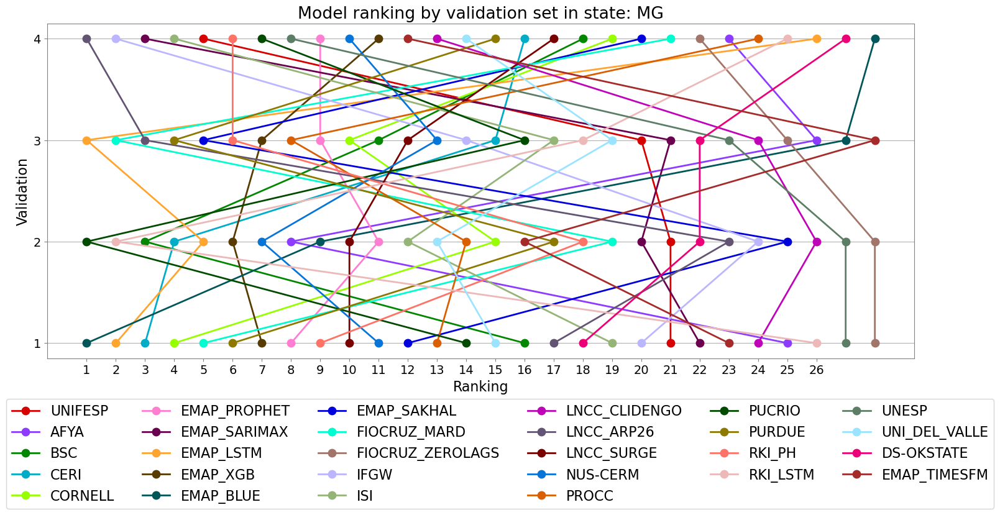

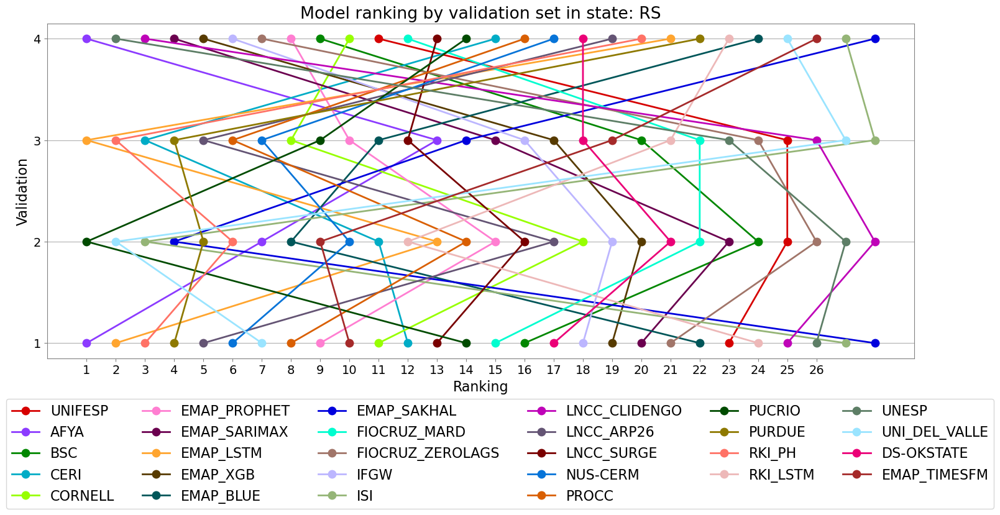

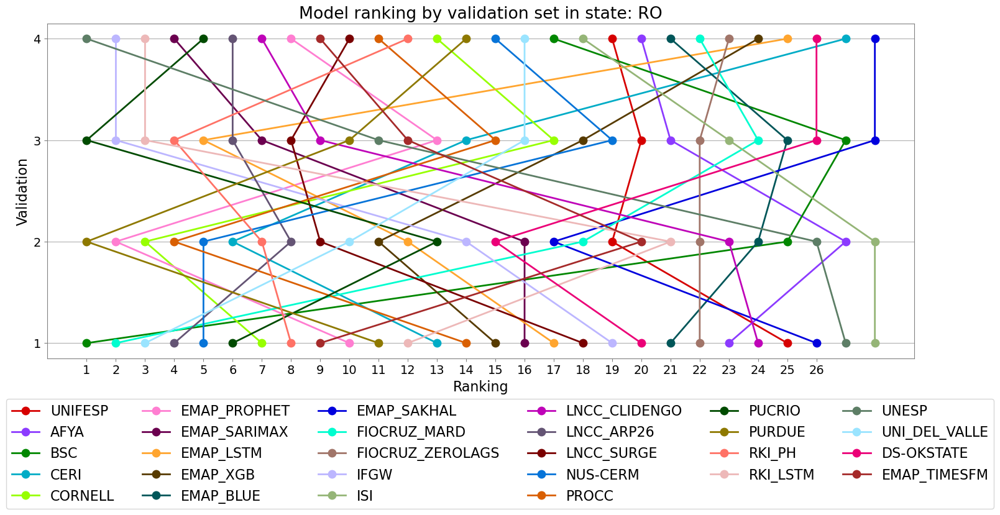

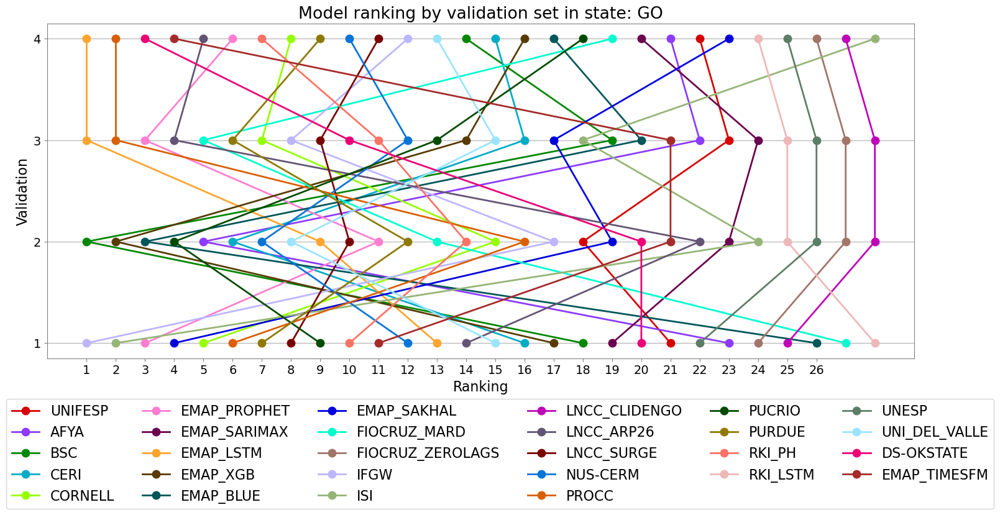

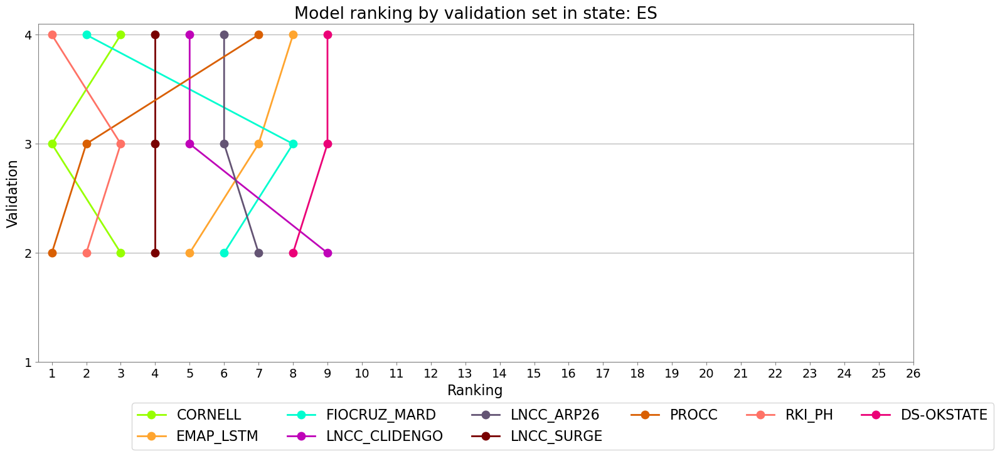

In [29]:
for state in df_preds.adm_1.unique(): 
    plot_rankplot(
        df=df_rank,
        colors=color_palette,
        x_col="rank",
        x_label="Ranking",
        title="Model ranking by validation set",
        region=state,
        x_ticks=np.arange(1, 27),
        x_lim=None,
            ncols_legend=6,
            bbox_to_anchor=(1.1, -0.1), 
            challenge = challenge,
            region_name = code_to_state[state]
    )


### Comp distributions - max cases, peak cases and peak height:

In [6]:
df_true_params = pd.read_csv(f'data/parameters_{challenge}.csv.gz')

df_true_params.head()

,state,validation,peak_week,total_cases,peak_height,peak_height_model,t_ini
0,11,1,17.912460,13281,864,750.147209,1
1,11,2,20.624851,5583,604,424.351398,6
2,11,3,28.967172,2553,142,113.486196,1
3,11,4,23.444633,1472,72,64.545081,1
4,12,1,22.992623,4735,288,236.612882,1


In [7]:
df_pars = pd.read_csv(f'predictions/new_metrics_{challenge}_new.csv.gz')
df_pars['model'] = df_pars['model'].replace(rename_models)
df_pars.head()

,model,validation,state,season_total_p25,season_total_p50,season_total_p975,season_peak_p25,season_peak_p50,season_peak_p975,r0_dist_p25,...,pico_dist_p25,pico_dist_p50,pico_dist_p975,t_ini_dist_p25,t_ini_dist_p50,t_ini_dist_p975,max_c_dist_p25,max_c_dist_p50,max_c_dist_p975,adm_1
0,ISI,2,12.0,8155.220843,9666.404427,11588.776658,225.289613,295.884608,419.352327,1.255347,...,29.934870,31.934181,35.000000,1.0,1.0,1.000,221.703746,271.983601,316.168189,NaN
1,ISI,3,12.0,5296.213880,6433.353223,7836.201734,148.828929,190.215776,248.274815,1.259569,...,29.806261,32.044642,34.895799,1.0,1.0,1.000,141.684160,175.709042,209.287538,NaN
2,ISI,4,12.0,7235.298114,8421.714410,9572.018224,199.337666,244.680701,301.015333,1.259767,...,30.060873,31.744612,34.252873,1.0,1.0,1.000,199.472020,222.530214,257.894208,NaN
3,PURDUE,2,12.0,2120.596418,6765.841749,28221.394693,144.663450,611.092154,4306.154039,1.109418,...,7.888542,18.482081,33.183729,1.0,1.0,5.525,74.984244,386.932102,2199.990377,NaN
4,PURDUE,3,12.0,1518.752445,5766.735068,25714.256030,98.427024,478.604529,3005.435595,1.236723,...,11.531725,19.721003,31.194712,1.0,1.0,5.525,54.121028,342.182133,1735.561044,NaN


/home/eduardocorrea/Documentos/analises_3rd_IMDC/viz.py:1105: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(


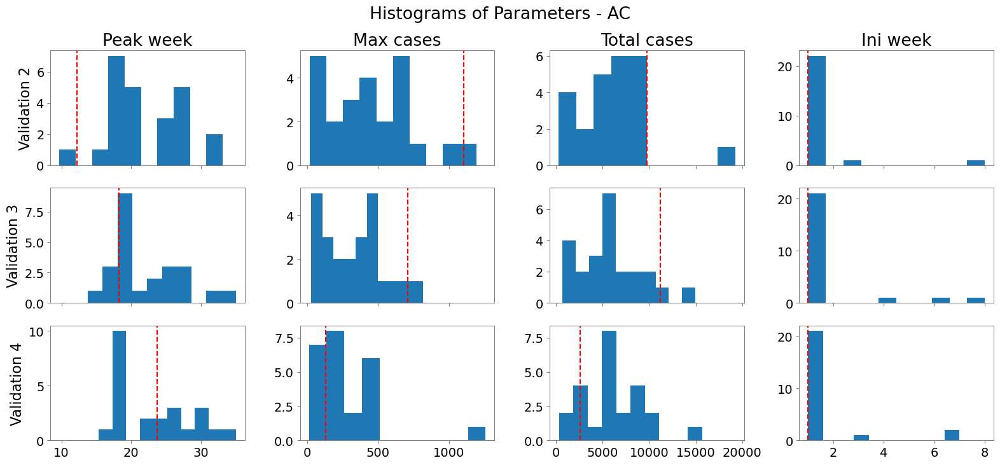

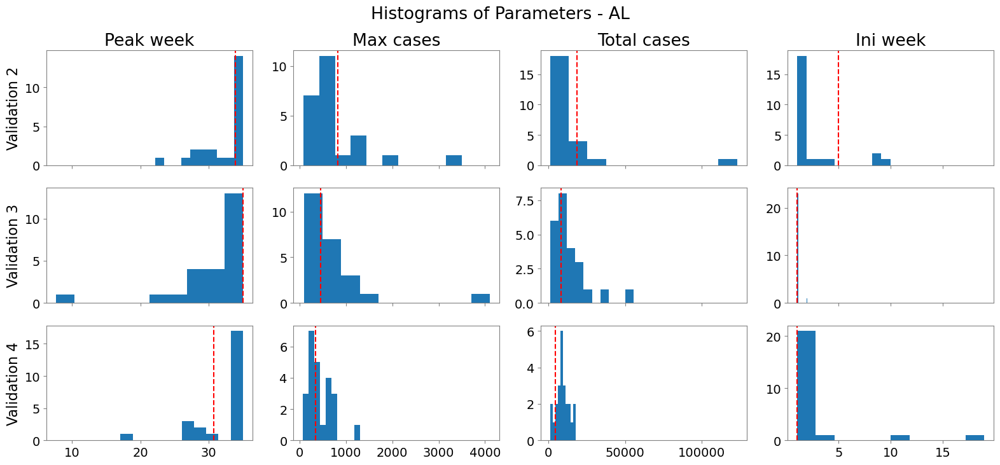

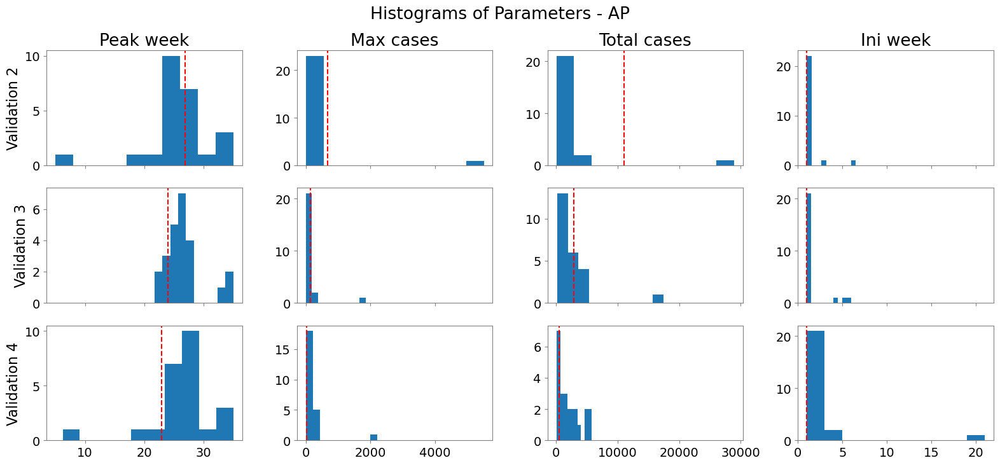

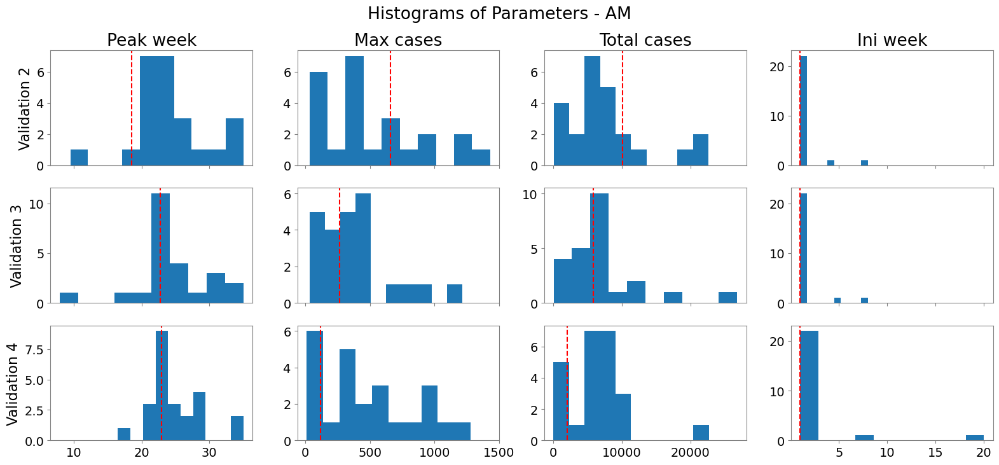

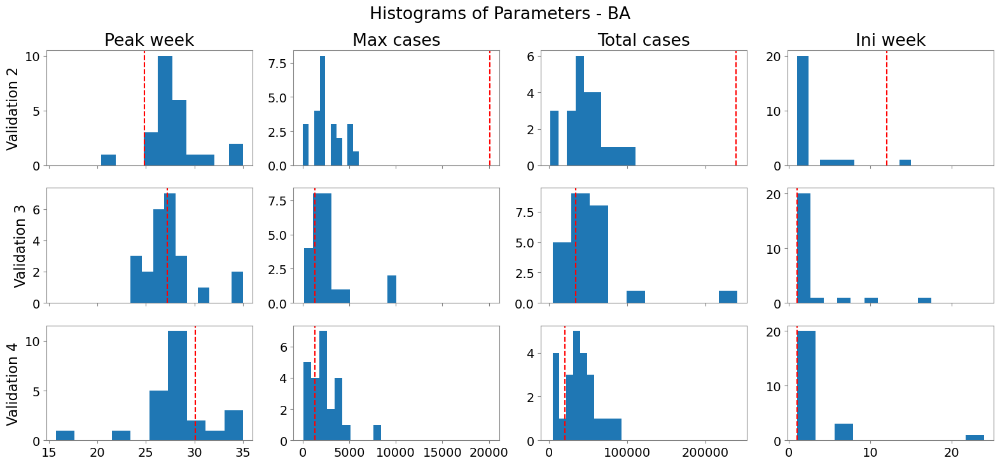

...

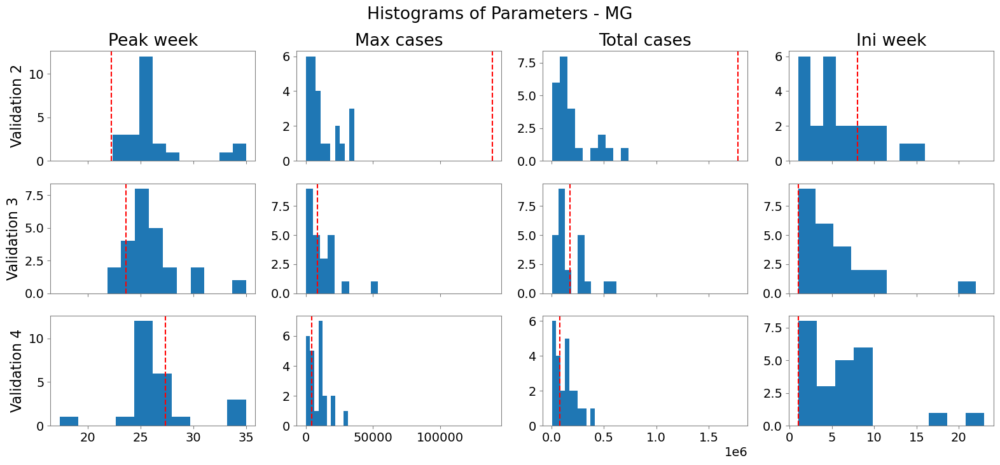

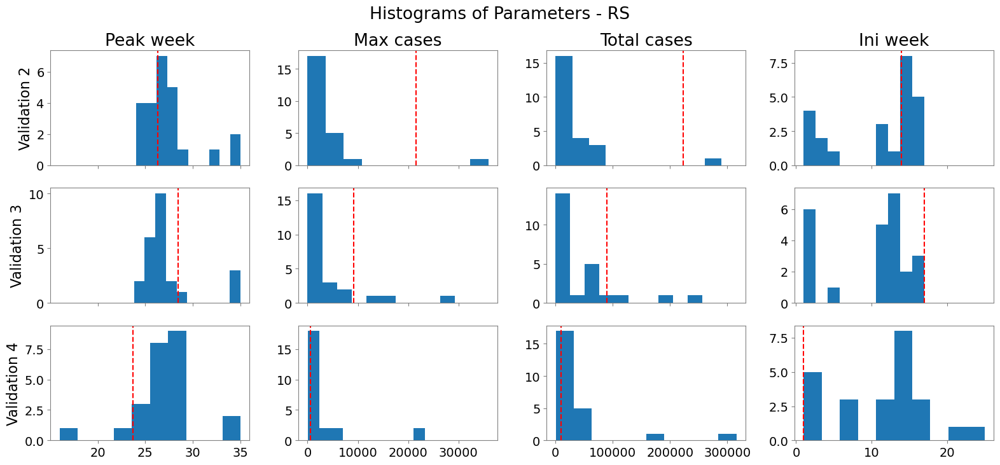

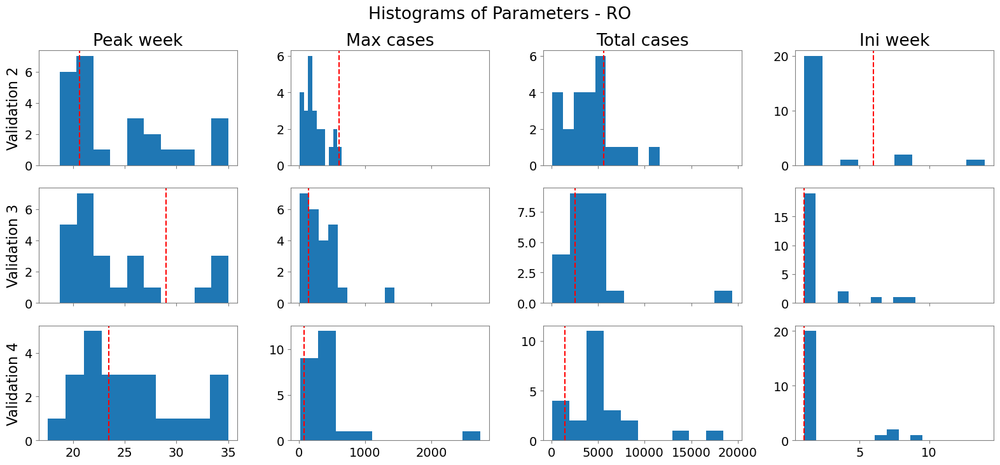

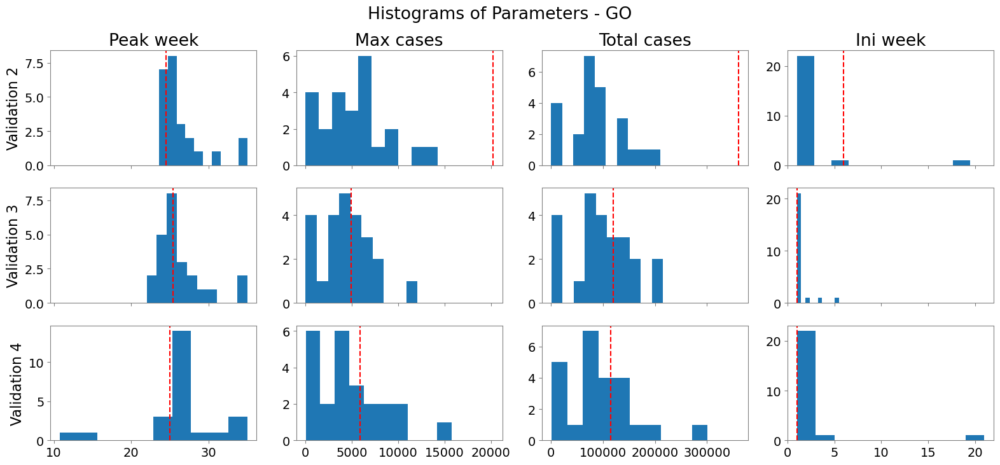

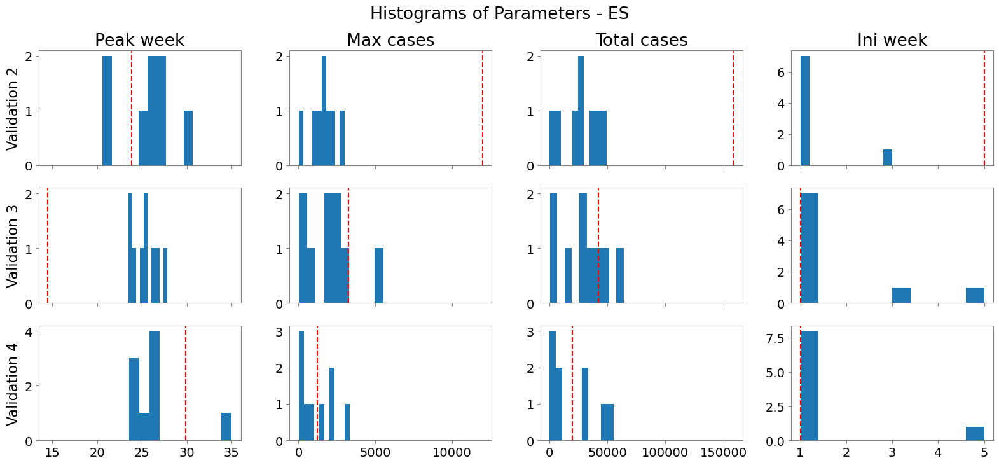

In [8]:
for state in df_preds.adm_1.unique():

    fig, ax = plot_parameter_histograms(df_true_params,
        df_pars,
        region =state, label_title=code_to_state[state])
    
    plt.savefig(f'figures/hist_pars_{state}_{challenge}.png', dpi = 400, bbox_inches = 'tight')

adm_1 = 33 
validation = 2

for adm_1 in df_pars.state.unique(): 

    for validation in [2,3,4]: 

        _,ax = plt.subplots(4,1, figsize = (15, 9), sharex= True)


        plot_par_bar(ax[0], 'peak_week', adm_1, validation, df_pars, df_true_params)

        plot_par_bar(ax[1], 't_ini', adm_1, validation, df_pars, df_true_params)

        plot_par_bar(ax[2], 'peak_height', adm_1, validation, df_pars, df_true_params)

        plot_par_bar(ax[3], 'total_cases', adm_1, validation, df_pars, df_true_params)

        labels = [tick.get_text() for tick in ax[3].get_xticklabels()]

        labels = [label.replace("_", "\n", 1) for label in labels]
        ax[3].set_xticklabels(labels)

        ax[3].tick_params(axis='x', labelrotation=90)

        plt.savefig(f'figures/bar_pars_{adm_1}_{validation}_{challenge}.png', dpi = 300, bbox_inches = 'tight')

        plt.close()